# Import packages & Load functions and data

In [1]:
import pysam
import os, glob
import random
import subprocess
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
DIR_data                = f'/home/18parkky/data/aml/paper'
DIR_genefusion_results  = f'{DIR_data}/genefusion_results'

In [ ]:
def check_log(PATH_log, barcode):
    with open(PATH_log, 'r') as f:
        for line in f.readlines():
            if f'No gene fusion for {barcode}!' in line.strip():
                return True 
    return False

# Figure 7b. SEGUE results

In [14]:
DIR_genefusion_results

SEGUE_results = list()
for DIR_run in sorted(glob.glob(f'{DIR_genefusion_results}/SEGUE/run*')):
    PATH_log = f'{DIR_run}/3_GeneFusion.log'

    list_DIR_out_per_barcode = glob.glob(f'{DIR_run}/3_GeneFusion/barcode*')
    for DIR_out_per_barcode in list_DIR_out_per_barcode:
        barcode = os.path.basename(DIR_out_per_barcode)
        PATH_GeneFusion_CallResults = f'{DIR_out_per_barcode}/{barcode}.GeneFusion.All.tsv'
        if os.path.exists(PATH_GeneFusion_CallResults)==False:
            print(f'No gene fusion detected for {barcode}')
            continue 

        GeneFusion_CallRes = pd.read_csv(PATH_GeneFusion_CallResults, sep='\t')
        GeneFusion_CallRes['SampleID'] = barcode
        SEGUE_results.append( GeneFusion_CallRes )

SEGUE_results = pd.concat(SEGUE_results)
SEGUE_results.reset_index(inplace=True, drop=True)

# Fusions known to exist
dict_SampleID_to_TrueGeneFusion = {
    'barcode39' : ['ABL1::BCR'],
    'barcode53' : ['ABL1::BCR'],
    'barcode20' : ['ABL1::BCR', 'CBFB::MYH11'],

    'barcode09' : ['CBFB::MYH11'],
    'barcode16' : ['CBFB::MYH11'],
    'barcode59' : ['CBFB::MYH11'],

    'barcode57' : ['KMT2A::MLLT10'],

    'barcode74' : ['KMT2A::MLLT3'],
    'barcode33' : ['KMT2A::MLLT3'],
    'barcode47' : ['KMT2A::MLLT3'],

    'barcode11' : ['PML::RARA'],
    'barcode15' : ['PML::RARA'],
    'barcode56' : ['PML::RARA'],

    'barcode12' : ['RUNX1::RUNX1T1'],
    'barcode52' : ['RUNX1::RUNX1T1'],
    'barcode45' : ['RUNX1::RUNX1T1'],
}

SEGUE_results['TrueKnown'] = [ bool(tup.GeneFusion in dict_SampleID_to_TrueGeneFusion.get(tup.SampleID, list())) for tup in SEGUE_results.itertuples() ]
SEGUE_results[(SEGUE_results['TrueKnown']==True)].sort_values('GeneFusion').reset_index()

,index,GeneFusion,known,n,std1,std2,log_n,log_std1,log_std2,log_std_avg,SampleID,TrueKnown
0,564,ABL1::BCR,True,368,1810,3943,2.567026,3.257918,3.595937,3.759970,barcode53,True
1,693,ABL1::BCR,True,40,430,388,1.612784,2.634477,2.589950,2.913284,barcode39,True
2,320,CBFB::MYH11,True,139,306,731,2.146128,2.487138,2.864511,3.016197,barcode09,True
3,723,CBFB::MYH11,True,57,406,754,1.763428,2.609594,2.877947,3.064832,barcode59,True
4,799,CBFB::MYH11,True,25,359,781,1.414973,2.556303,2.893207,3.057286,barcode20,True
5,708,KMT2A::MLLT10,True,53,2645,2475,1.732394,3.422590,3.393751,3.709355,barcode57,True
6,450,KMT2A::MLLT3,True,420,237,541,2.624282,2.376577,2.733999,2.891537,barcode47,True
7,668,KMT2A::MLLT3,True,104,414,394,2.021189,2.618048,2.596597,2.907949,barcode33,True
8,778,KMT2A::MLLT3,True,139,413,397,2.146128,2.617000,2.599883,2.909021,barcode74,True
9,53,PML::RARA,True,270,409,414,2.432969,2.612784,2.618048,2.915927,barcode11,True


Events: 17 | detected: 15 | undetected: 2 | patients: 16
  undetected: ABL1::BCR (patient 20)
  undetected: CBFB::MYH11 (patient 16)


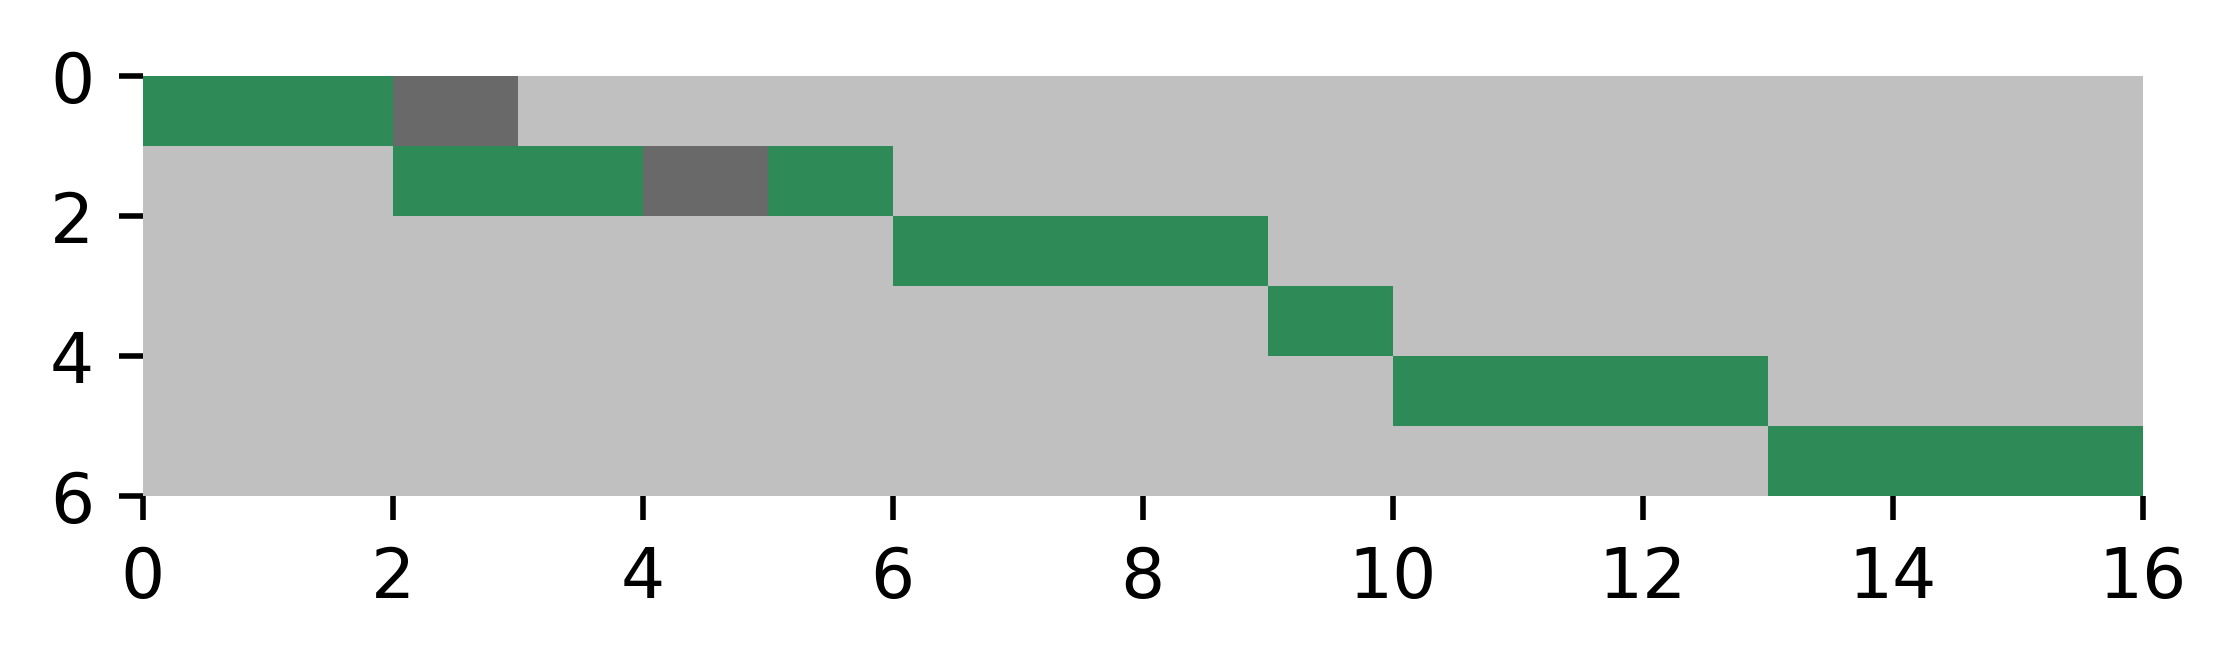

In [ ]:
# This code block is purely for visualizaiton - no analysis is performed.

# ================================ CONFIG =====================================
# Display order, exactly as drawn. IDs are strings so "09" keeps its zero.
PATIENT_ORDER = ["39", "53", "20", "09", "16", "59", "33", "47",
                 "74", "57", "11", "15", "56", "12", "45", "52"]           # left -> right
FUSION_ORDER  = ["ABL1::BCR", "CBFB::MYH11", "KMT2A::MLLT3",
                 "KMT2A::MLLT10", "PML::RARA", "RUNX1::RUNX1T1"]          # top -> bottom

# One line per known fusion event: (fusion, patient ID, detected?)
EVENTS = [
    ("ABL1::BCR",      "39", True),
    ("ABL1::BCR",      "53", True),
    ("ABL1::BCR",      "20", False),
    ("CBFB::MYH11",    "20", True),
    ("CBFB::MYH11",    "09", True),
    ("CBFB::MYH11",    "16", False),
    ("CBFB::MYH11",    "59", True),
    ("KMT2A::MLLT3",   "33", True),
    ("KMT2A::MLLT3",   "47", True),
    ("KMT2A::MLLT3",   "74", True),
    ("KMT2A::MLLT10",  "57", True),
    ("PML::RARA",      "11", True),
    ("PML::RARA",      "15", True),
    ("PML::RARA",      "56", True),
    ("RUNX1::RUNX1T1", "12", True),
    ("RUNX1::RUNX1T1", "45", True),
    ("RUNX1::RUNX1T1", "52", True),
]

# Colours (sampled from the original panel)
COLOR_DETECTED   = "seagreen"
COLOR_UNDETECTED = "dimgray"
COLOR_NO_EVENT   = "silver"

# Geometry
CELL_W_IN = 0.25                         # cell width  (inches)
CELL_H_IN = 0.14                         # cell height (inches)
SHOW_DPI  = 500                          # on-screen resolution only
# =============================================================================

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


def validate():
    """Fail loudly on anything that would otherwise be silently mis-drawn."""
    problems = []
    for name, order in (("PATIENT_ORDER", PATIENT_ORDER), ("FUSION_ORDER", FUSION_ORDER)):
        dupes = sorted({x for x in order if order.count(x) > 1})
        if dupes:
            problems.append(f"{name} has duplicates: {dupes}")

    seen = set()
    for i, event in enumerate(EVENTS, start=1):
        if len(event) != 3:
            problems.append(f"EVENTS line {i}: expected (fusion, patient, detected), got {event!r}")
            continue
        fusion, patient, detected = event
        if fusion not in FUSION_ORDER:
            problems.append(f"EVENTS line {i}: fusion {fusion!r} is not in FUSION_ORDER")
        if patient not in PATIENT_ORDER:
            problems.append(f"EVENTS line {i}: patient {patient!r} is not in PATIENT_ORDER "
                            f"(IDs must be strings, e.g. '09')")
        if not isinstance(detected, bool):
            problems.append(f"EVENTS line {i}: detected must be True/False, got {detected!r}")
        if (fusion, patient) in seen:
            problems.append(f"EVENTS line {i}: duplicate event {fusion} / patient {patient}")
        seen.add((fusion, patient))

    if problems:
        # raise, not sys.exit: sys.exit kills the kernel connection in some setups
        raise ValueError("Config error(s):\n  - " + "\n  - ".join(problems))

    for patient in PATIENT_ORDER:
        if not any(e[1] == patient for e in EVENTS):
            print(f"WARNING: patient {patient} has no events (empty column)")
    for fusion in FUSION_ORDER:
        if not any(e[0] == fusion for e in EVENTS):
            print(f"WARNING: fusion {fusion} has no events (empty row)")


def print_tally():
    """Counts to check against the manuscript text."""
    n_total = len(EVENTS)
    n_det = sum(e[2] for e in EVENTS)
    print(f"Events: {n_total} | detected: {n_det} | undetected: {n_total - n_det} "
          f"| patients: {len(PATIENT_ORDER)}")
    for fusion, patient, detected in EVENTS:
        if not detected:
            print(f"  undetected: {fusion} (patient {patient})")


def draw():
    """Draw the matrix alone and return (fig, ax) for further tweaking."""
    n_rows, n_cols = len(FUSION_ORDER), len(PATIENT_ORDER)

    # Figure is exactly the grid: no margins, so the displayed extent is the
    # matrix itself and the cells keep their true aspect ratio.
    fig = plt.figure(figsize=(n_cols * CELL_W_IN, n_rows * CELL_H_IN), dpi=SHOW_DPI)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)                        # first fusion at the top

    # Grey background, then one rectangle per run of same-state cells
    # (merged runs avoid hairline seams between cells).
    ax.add_patch(Rectangle((0, 0), n_cols, n_rows, facecolor=COLOR_NO_EVENT,
                           edgecolor="none", zorder=0))
    state = {(f, p): d for f, p, d in EVENTS}
    for r, fusion in enumerate(FUSION_ORDER):
        c = 0
        while c < n_cols:
            s = state.get((fusion, PATIENT_ORDER[c]))
            run = 1
            while c + run < n_cols and state.get((fusion, PATIENT_ORDER[c + run])) == s:
                run += 1
            if s is not None:
                ax.add_patch(Rectangle((c, r), run, 1, edgecolor="none", zorder=1,
                                       facecolor=COLOR_DETECTED if s else COLOR_UNDETECTED))
            c += run

    # ax.set_xticks([])
    # ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

    return fig, ax


validate()
print_tally()
fig, ax = draw()
plt.show()

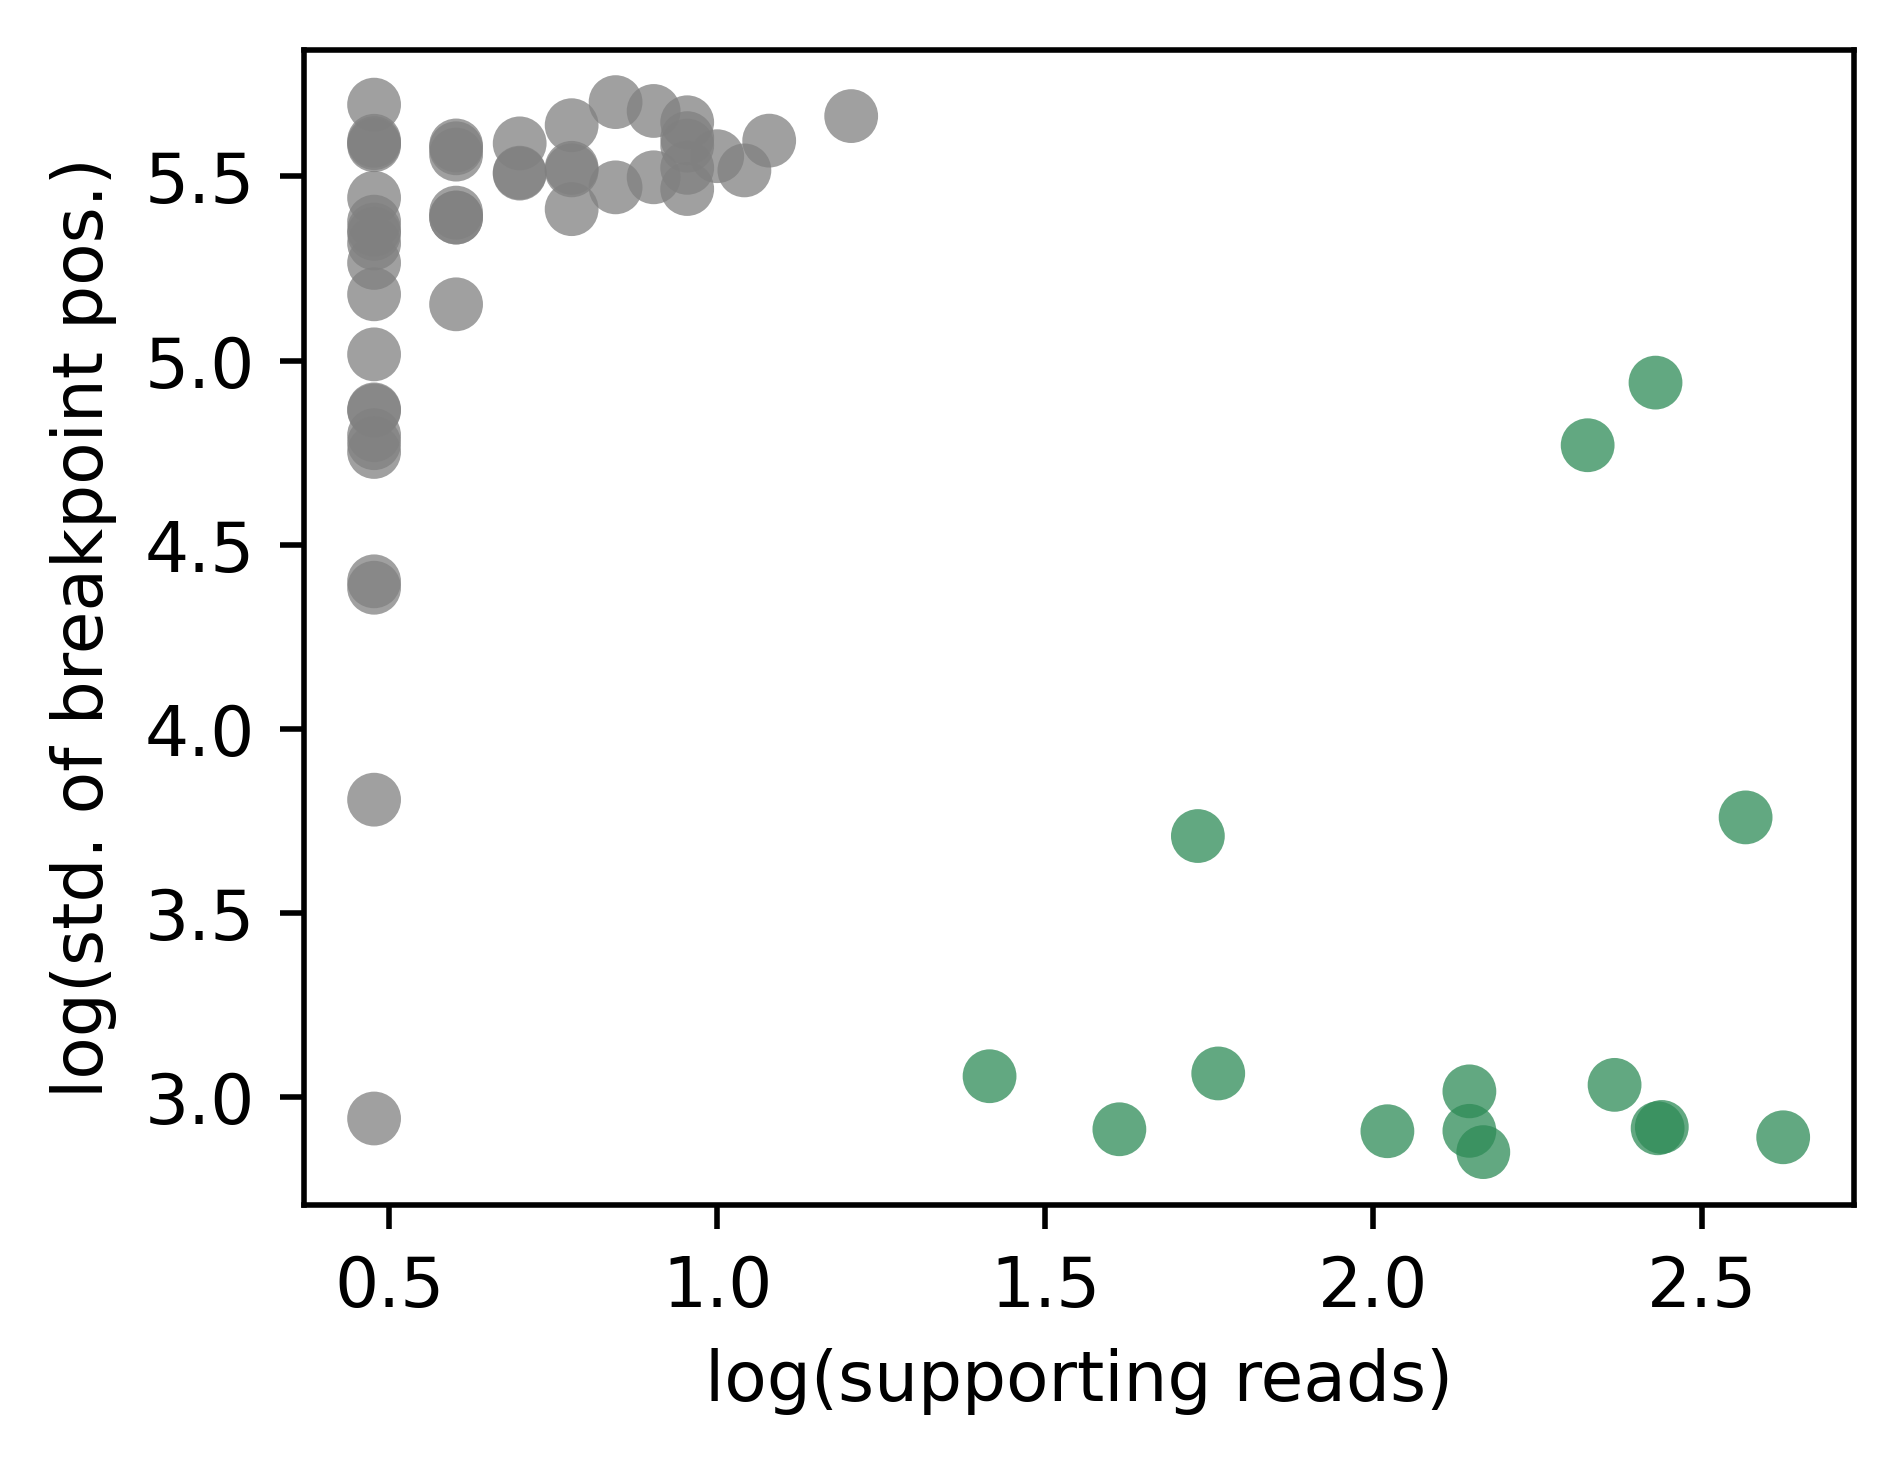

In [16]:
plt.figure(figsize=(4, 3), dpi=500)
sns.scatterplot(data=SEGUE_results[(SEGUE_results['known']==True)], 
                x='log_n', y='log_std_avg', hue='TrueKnown', legend=None, palette={True: 'seagreen', False:'gray'}, 
                linewidth=0, alpha=0.75, s=60)
plt.xlabel('log(supporting reads)');
plt.ylabel('log(std. of breakpoint pos.)');

# Figure 7c. Comparison with other tools

## Load results

In [31]:
PATH_FusionSeeker_out   = f'{DIR_genefusion_results}/other_tools/FusionSeeker/results.tsv'
PATH_GFSeeker_out       = f'{DIR_genefusion_results}/other_tools/GFSeeker/results.tsv'
PATH_JAFFAL_out         = f'{DIR_genefusion_results}/other_tools/JAFFAL/results.tsv'
PATH_LongGF_out         = f'{DIR_genefusion_results}/other_tools/LongGF/results.tsv'

FusionSeeker_results    = pd.read_csv(PATH_FusionSeeker_out, sep='\t',)
GFSeeker_results        = pd.read_csv(PATH_GFSeeker_out, sep='\t',)
JAFFAL_results          = pd.read_csv(PATH_JAFFAL_out, sep='\t',)
LongGF_results          = pd.read_csv(PATH_LongGF_out, sep='\t')

results = list()
for tup in LongGF_results.itertuples():
    geneA, geneB = sorted(tup.fusion.split('::'))
    if geneA == tup.fusion.split('::')[0]:
        bp1 = tup.bp1 
        bp2 = tup.bp2 
    else:
        bp1 = tup.bp2
        bp2 = tup.bp1 
    results.append( [geneA, geneB, f'{geneA}::{geneB}', bp1, bp2, tup.reads, 'NotAvailable', tup.SampleID, 'LongGF'] )

for tup in FusionSeeker_results.itertuples():
    geneA, geneB = sorted([list(tup)[1], list(tup)[2]])[0], sorted([list(tup)[1], list(tup)[2]])[1], 
    if geneA == list(tup)[1]:
        bp1 = f'{list(tup)[4]}:{list(tup)[5]}'
        bp2 = f'{list(tup)[6]}:{list(tup)[7]}'
    else:
        bp1 = f'{list(tup)[6]}:{list(tup)[7]}'
        bp2 = f'{list(tup)[4]}:{list(tup)[5]}'
    results.append( [geneA, geneB, f'{geneA}::{geneB}', bp1, bp2, tup.num_reads, 'NotAvailable', tup.SampleID, 'FusionSeeker'] )

for tup in JAFFAL_results.itertuples():
    geneA, geneB = sorted(list(tup)[2].split('::'))
    if geneA == list(tup)[2].split('::')[0]:
        bp1 = f'{list(tup)[3]}:{list(tup)[4]}'
        bp2 = f'{list(tup)[6]}:{list(tup)[7]}'
    else:
        bp1 = f'{list(tup)[6]}:{list(tup)[7]}'
        bp2 = f'{list(tup)[3]}:{list(tup)[4]}'
    results.append( [geneA, geneB, f'{geneA}::{geneB}', bp1, bp2, list(tup)[11], tup.classification, tup.SampleID, 'JAFFAL'] )

for tup in GFSeeker_results.itertuples():
    geneA, geneB = sorted([list(tup)[1], list(tup)[2]])[0], sorted([list(tup)[1], list(tup)[2]])[1], 

    if geneA == list(tup)[1]:
        bp1 = list(tup)[3].split(';')[0].strip()
        bp2 = list(tup)[3].split(';')[1].strip()
    else:
        bp1 = list(tup)[3].split(';')[1].strip()
        bp2 = list(tup)[3].split(';')[0].strip()

    results.append( [geneA, geneB, f'{geneA}::{geneB}', bp1, bp2, list(tup)[6], list(tup)[7], tup.SampleID, 'GFSeeker'] )

for tup in SEGUE_results.itertuples():
    geneA, geneB = tup.GeneFusion.split('::')
    results.append( [geneA, geneB, tup.GeneFusion, None, None, tup.n, None, tup.SampleID, 'in-house'] )


results = pd.DataFrame(results, columns=['geneA', 'geneB', 'fusion', 'bp1', 'bp2', 'num_reads', 'rank_class', 'SampleID', 'tool'])
results.replace({'CBFB::NDE1' : 'CBFB::MYH11'}, inplace=True)   # FusionSeeker labels CBFB::MYH11 as CBFB::NDE1. NDE1 and MYH11 share genomic regions
results['TrueKnown'] = [ bool(tup.fusion in dict_SampleID_to_TrueGeneFusion.get(tup.SampleID, list())) for tup in results.itertuples() ]
results.tail(2)

,geneA,geneB,fusion,bp1,bp2,num_reads,rank_class,SampleID,tool,TrueKnown
1854,RUNX1,STAG2,RUNX1::STAG2,None,None,2,None,barcode22,in-house,False
1855,EBF1,RUNX1,EBF1::RUNX1,None,None,4,None,barcode24,in-house,False


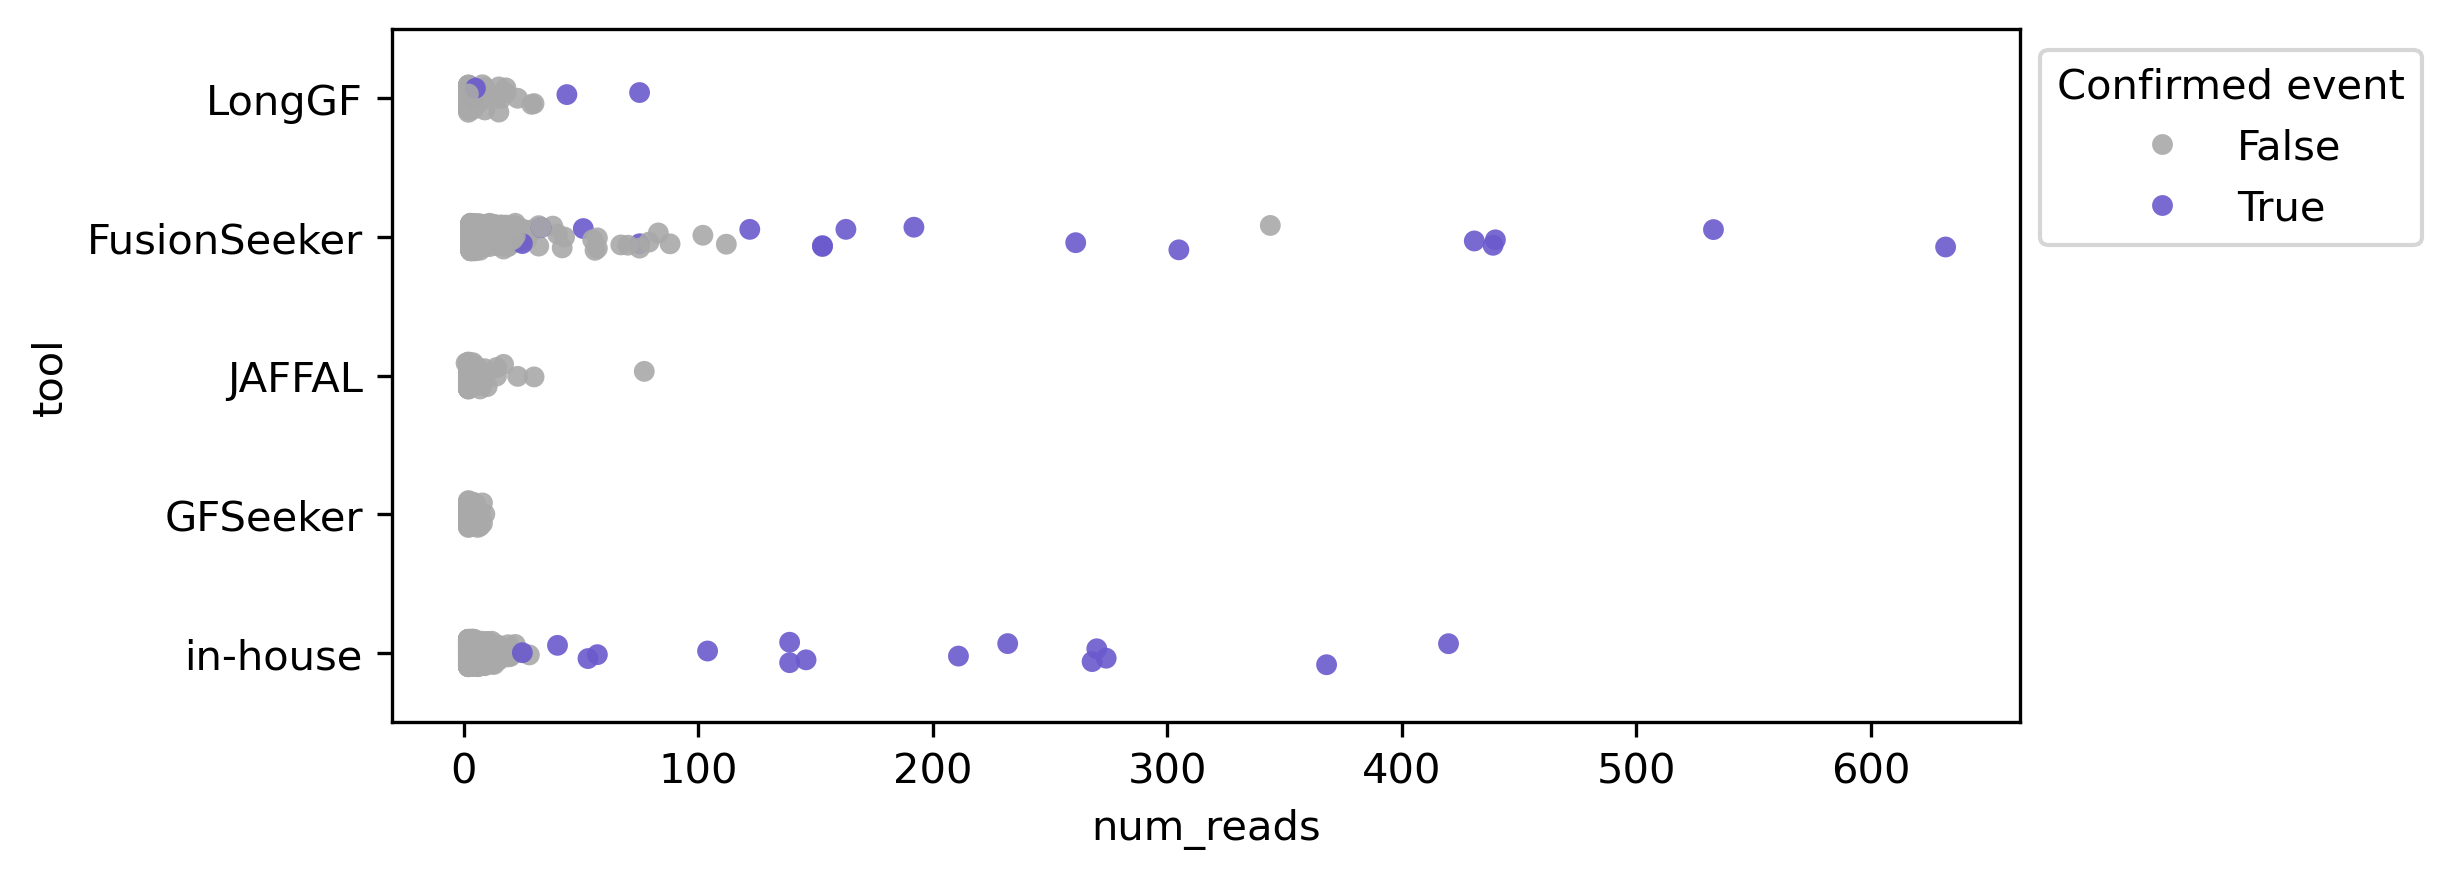

In [35]:
plt.figure(figsize=(7, 3), dpi=300)
ax = sns.stripplot(data=results[(results['num_reads']>=0)], y='tool', x='num_reads', 
                   alpha=0.9, hue='TrueKnown', palette={False : 'darkgrey', True : 'slateblue'},
                   )
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title='Confirmed event')

# Figure 7d. Metrics generated by SEGUE

In [37]:
SEGUE_results.head(1)

,GeneFusion,known,n,std1,std2,log_n,log_std1,log_std2,log_std_avg,SampleID,TrueKnown
0,ABL1::EBF1,False,2,48356,30412,0.477121,4.684459,4.483059,4.896355,barcode11,False


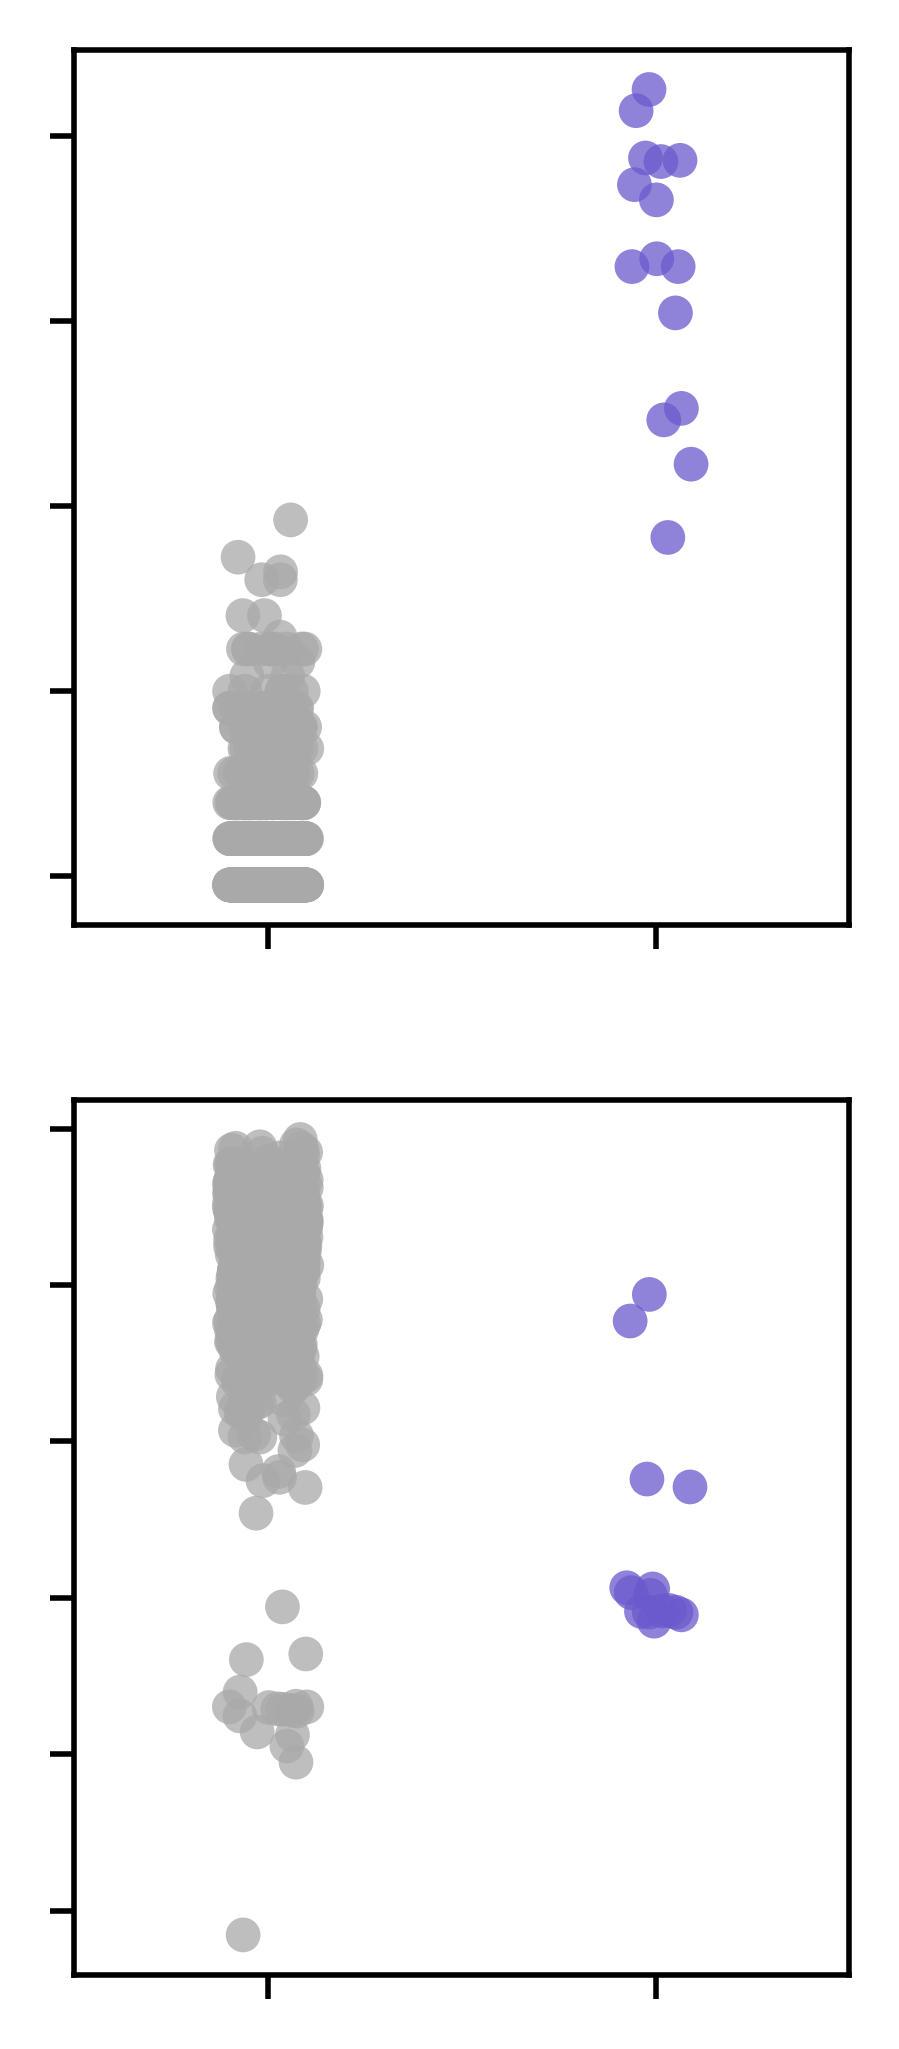

In [39]:
fig, axes = plt.subplots(2, 1, figsize=(2, 5), dpi=500, sharex=True,)
ax = sns.stripplot(SEGUE_results, x='TrueKnown', y='log_n',
                    alpha=0.75, 
                    # color={False : 'darkgrey', True : 'slateblue'}, 
                    hue='TrueKnown',
                    palette={False: 'darkgrey', True: 'slateblue'},
                    legend=None,
                    ax=axes[0],)
ax.set_xlabel('');
ax.set_ylabel('');
ax.set_xticklabels([]);
ax.set_yticklabels([]);

ax = sns.stripplot(SEGUE_results, x='TrueKnown', y='log_std_avg',
                    alpha=0.75, 
                    # color={False : 'darkgrey', True : 'slateblue'}, 
                    hue='TrueKnown',
                    palette={False: 'darkgrey', True: 'slateblue'},
                    legend=None,
                    ax=axes[1],)
ax.set_xlabel('');
ax.set_ylabel('');
ax.set_xticklabels([]);
ax.set_yticklabels([]);
